<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/Laysan_Albatross_Sex_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [69]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
)

RANDOM_STATE = 42
POSITIVE_LABEL = "H"

In [70]:
# Load datasets

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
sample_submission = pd.read_csv("/content/sample_submission.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

display(train.head())
display(test.head())
display(sample_submission.head())

Training shape: (94, 14)
Test shape: (41, 13)
Sample submission shape: (3, 2)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99
3,C58_2018,187.85,116.90,87.52,54.22,35.10,27.00,99.48,52.3,99.8,107.6,215.2,3.55
4,5E2_2018,182.67,116.40,87.24,54.57,33.59,25.40,96.43,53.4,100.3,110.1,220.2,3.06


,id,sexo
0,id_1,M
1,id_2,H
2,id_3,M


In [71]:
# Understanding data

print("Training information:")
print("-------------------------------------")
train.info()

print("\nTraining descriptive statistics:")
print("-------------------------------------")
display(train.describe(include="all").T)

print("\nTest information:")
print("-------------------------------------")
test.info()

print("\nTraining columns:", train.columns.tolist())
print("\nTest columns:", test.columns.tolist())

Training information:
-------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB

Training descriptive statistic

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,94,94,0J4_2016,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sexo,94,2,H,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitudCraneo,94.0,NaN,NaN,NaN,176.580106,5.443278,165.58,172.1875,176.915,180.525,191.21
longitudPico,94.0,NaN,NaN,NaN,110.130426,4.02892,102.71,106.835,110.07,113.2525,119.48
longitudNarina,94.0,NaN,NaN,NaN,82.936383,3.187515,74.82,80.2175,83.325,85.425,90.68
anchoCraneo,94.0,NaN,NaN,NaN,52.687553,2.226749,46.5,51.2075,52.475,54.3475,58.36
altoPico,94.0,NaN,NaN,NaN,32.535,1.383418,29.34,31.605,32.605,33.46,35.5
anchoPico,94.0,NaN,NaN,NaN,25.425319,1.439065,21.48,24.5,25.48,26.3725,28.7
tarso,94.0,NaN,NaN,NaN,90.88766,2.85098,84.04,88.66,91.035,92.57,99.69
longAlaCerrada,94.0,NaN,NaN,NaN,51.667021,1.18534,48.7,51.0,51.6,52.475,54.7



Test information:
-------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                41 non-null     object 
 1   longitudCraneo    41 non-null     float64
 2   longitudPico      41 non-null     float64
 3   longitudNarina    41 non-null     float64
 4   anchoCraneo       41 non-null     float64
 5   altoPico          41 non-null     float64
 6   anchoPico         41 non-null     float64
 7   tarso             41 non-null     float64
 8   longAlaCerrada    41 non-null     float64
 9   longAlaAbierta    41 non-null     float64
 10  mediaEnvergadura  41 non-null     float64
 11  envergadura       41 non-null     float64
 12  peso              41 non-null     float64
dtypes: float64(12), object(1)
memory usage: 4.3+ KB

Training columns: ['id', 'sexo', 'longitudCraneo', 'longitudPico', 'longitudNarin

,Count
sexo,
H,57
M,37


Target proportions:


,Proportion
sexo,
H,0.606383
M,0.393617


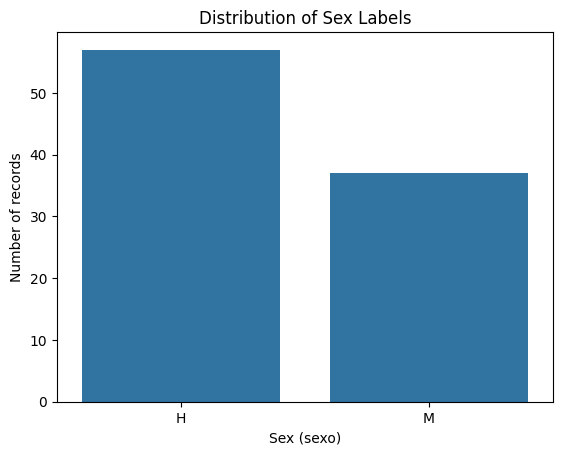

In [72]:
# Count of each class (H and M) in the target variable
target_counts = train["sexo"].value_counts()
display(target_counts.rename("Count").to_frame())

# Display the proportion of each class in the target variable
print("Target proportions:")
display(train["sexo"].value_counts(normalize=True).rename("Proportion").to_frame())

# Visualise the distribution of sex labels using a count plot
sns.countplot(data=train, x="sexo")
plt.title("Distribution of Sex Labels")
plt.xlabel("Sex (sexo)")
plt.ylabel("Number of records")
plt.show()

In [73]:
# Check for missing values in the training dataset
print("Missing values in training data:")
# Count the number of missing values in each column
display(train.isnull().sum().to_frame("Missing values"))

# Check for missing values in the test dataset
print("Missing values in test data:")
display(test.isnull().sum().to_frame("Missing values"))

# Check for duplicate rows in the training dataset
print("Duplicate training rows:", train.duplicated().sum())
# Check for duplicate IDs in the training dataset
print("Duplicate training IDs:", train["id"].duplicated().sum())
# Check for duplicate IDs in the test dataset
print("Duplicate test IDs:", test["id"].duplicated().sum())
# Check whether any IDs are common between training and test datasets
# Convert IDs into sets and find their intersection
print("Train/test ID overlap:", len(set(train["id"]) & set(test["id"])))

Missing values in training data:


,Missing values
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


Missing values in test data:


,Missing values
id,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0
longAlaAbierta,0


Duplicate training rows: 0
Duplicate training IDs: 0
Duplicate test IDs: 0
Train/test ID overlap: 0


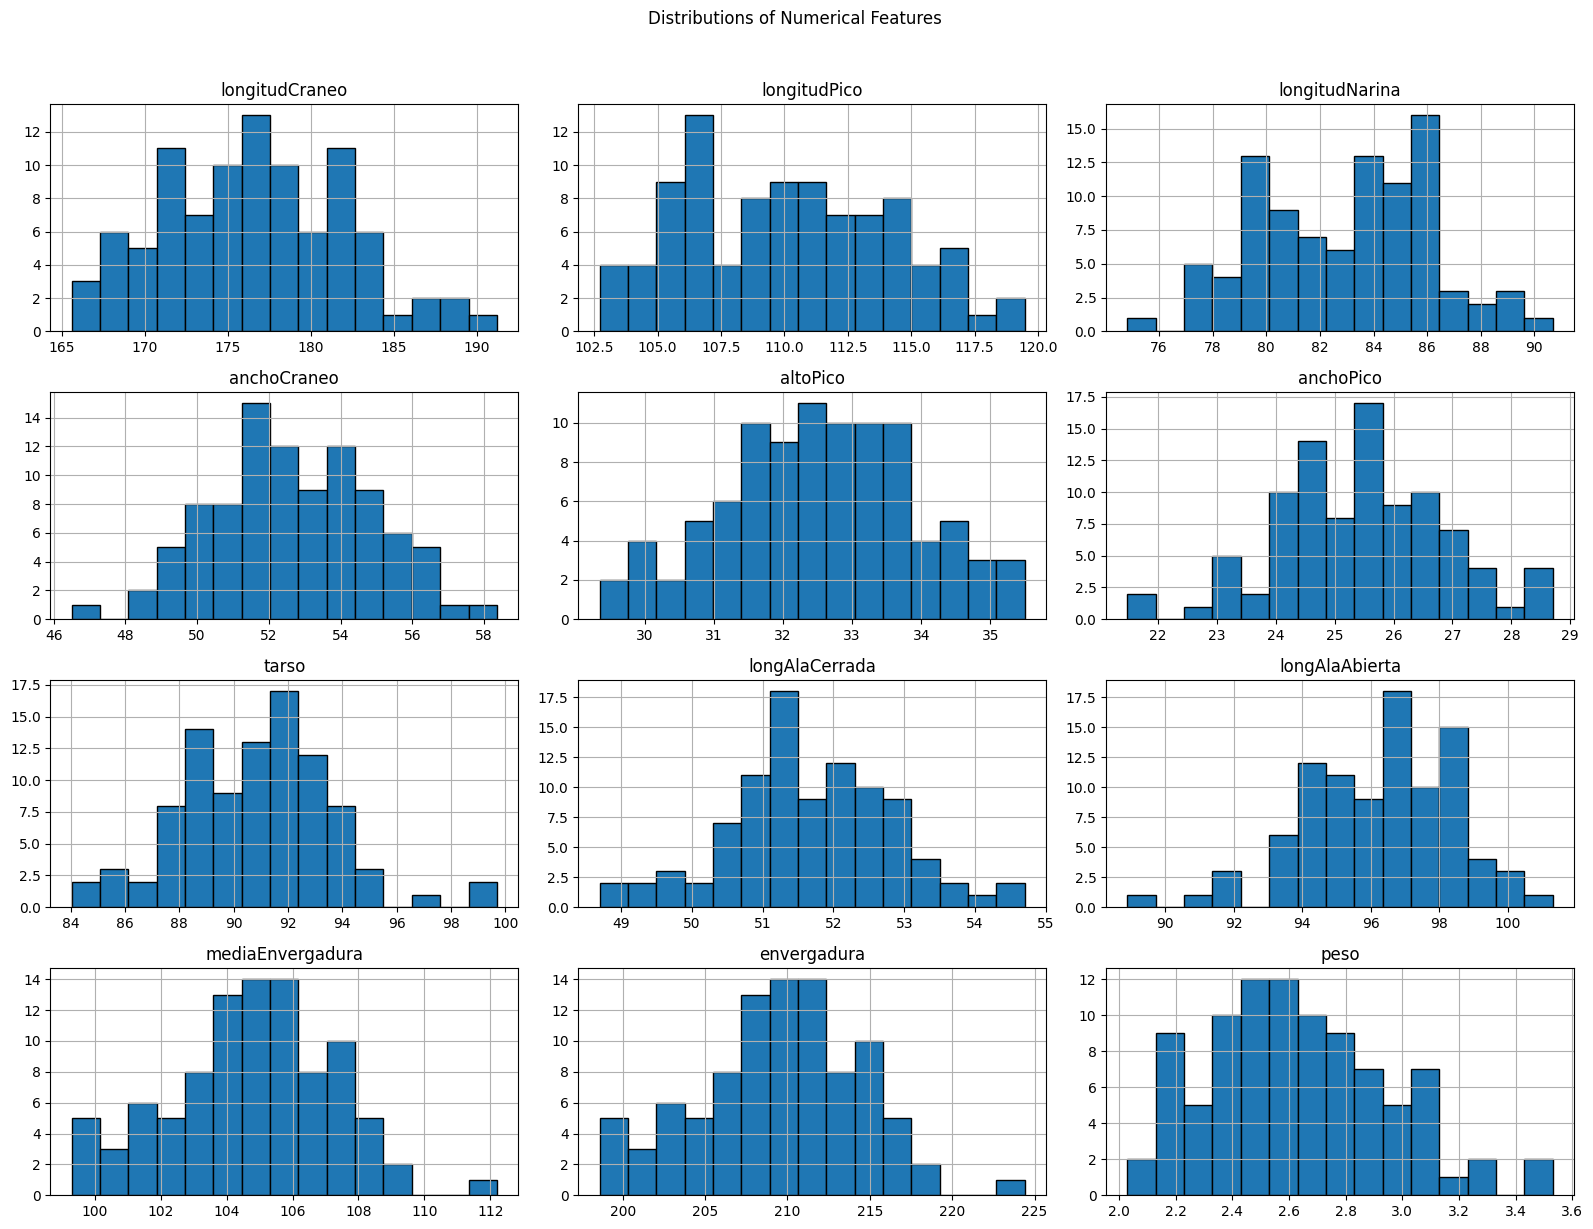

In [74]:
# Select all numerical feature columns, excluding the ID and target columns
feature_cols = [col for col in train.columns if col not in ["id", "sexo"]]

# Generate histograms to visualize the distribution of each numerical feature
train[feature_cols].hist(figsize=(16, 12), bins=15, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

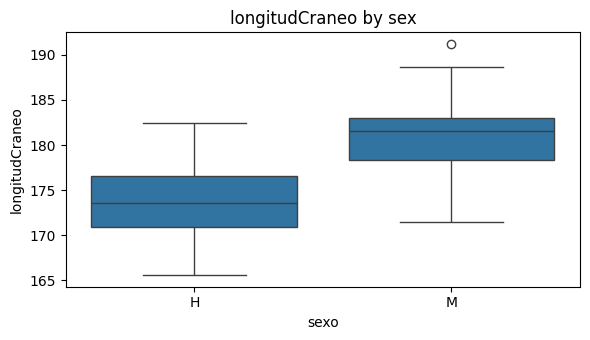

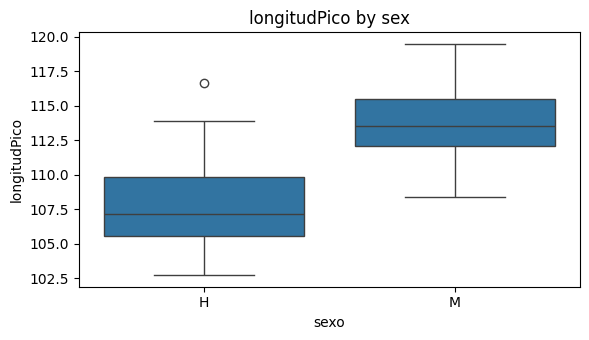

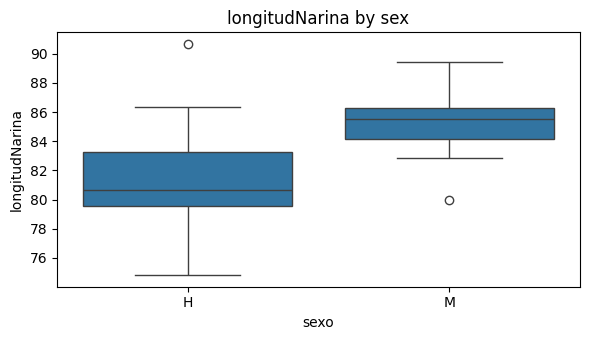

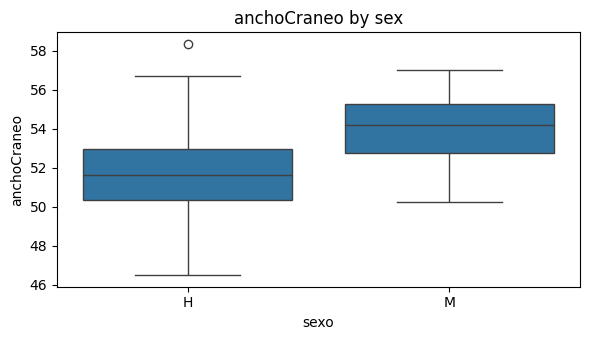

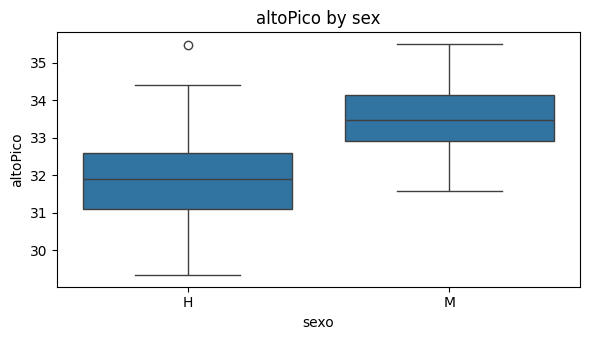

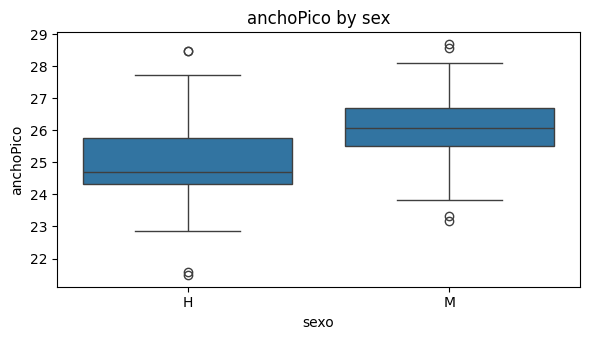

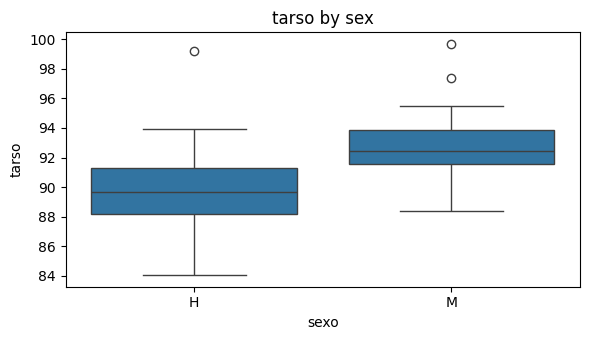

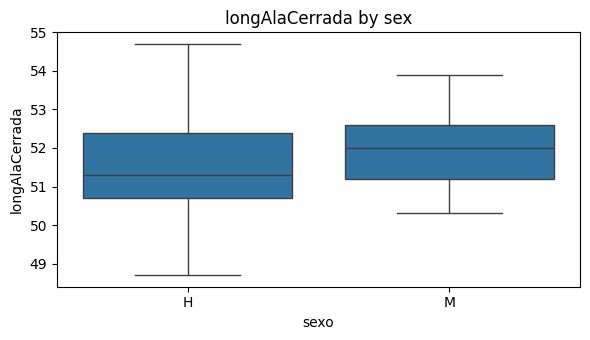

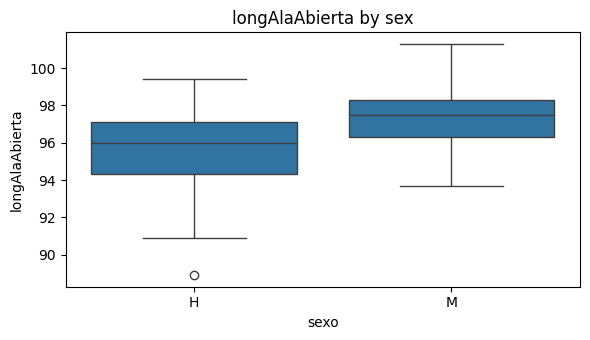

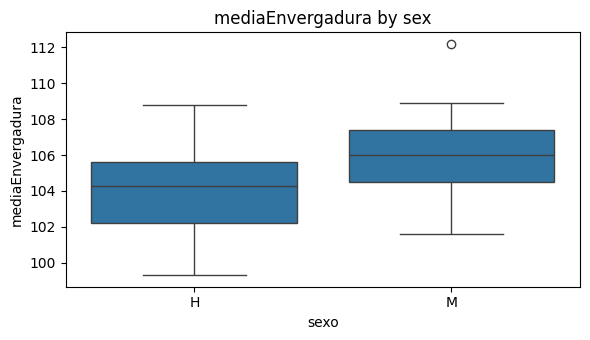

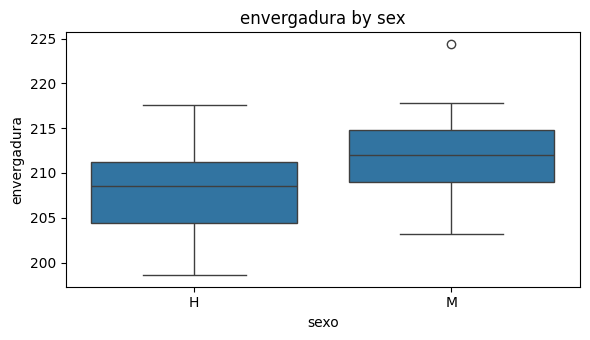

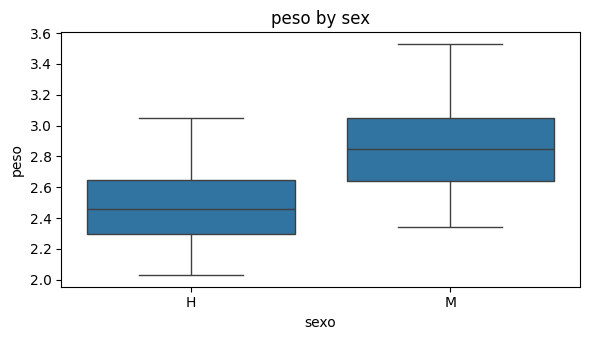

In [75]:
# Generate separate boxplots for each numerical feature to compare its distribution across sex categories
for col in feature_cols:
    plt.figure(figsize=(6, 3.5))
    sns.boxplot(data=train, x="sexo", y=col)
    plt.title(f"{col} by sex")
    plt.tight_layout()
    plt.show()

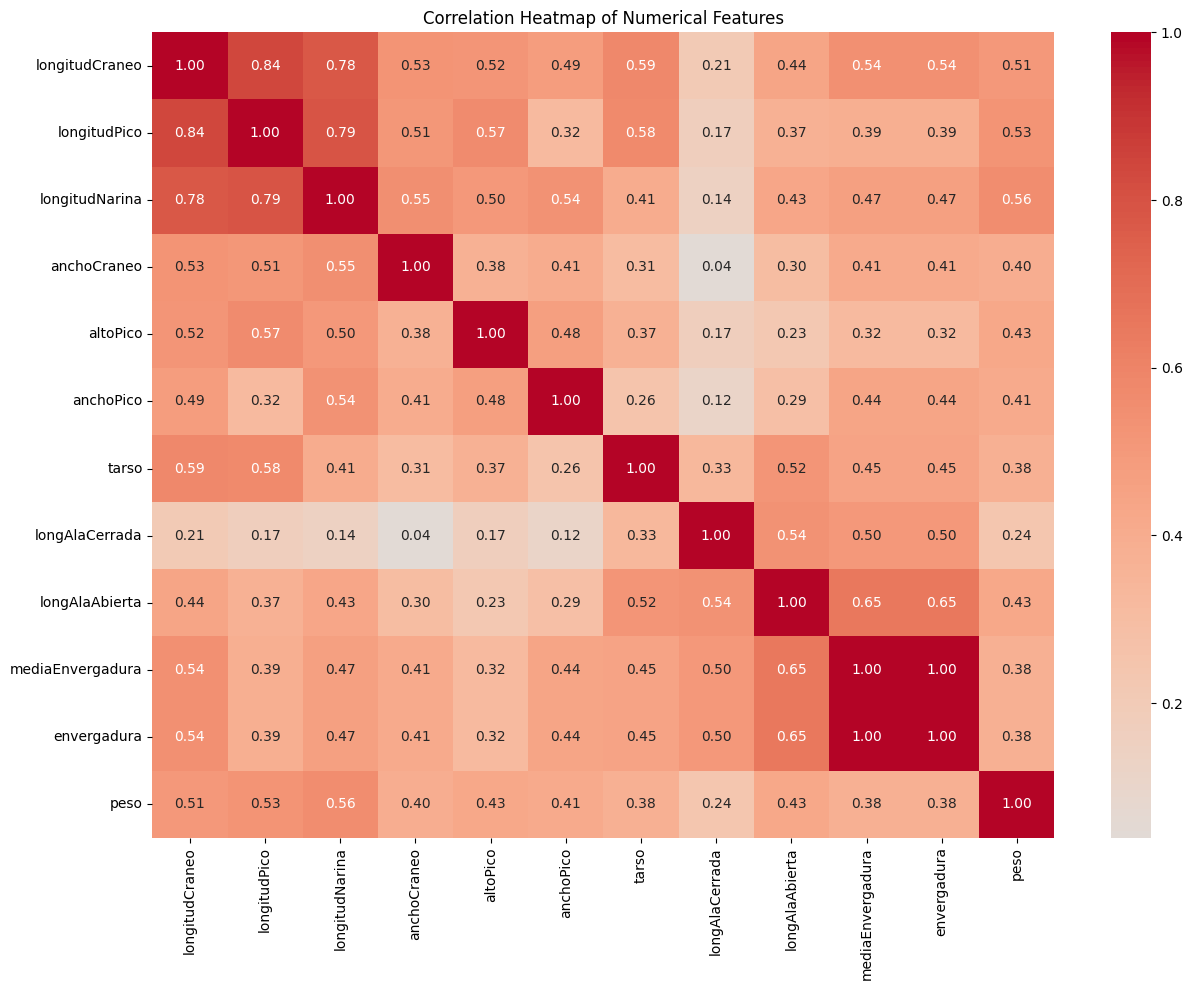

In [76]:
# Calculate the correlation matrix for all numerical features
plt.figure(figsize=(13, 10))
sns.heatmap(train[feature_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [77]:
# Identify outliers using IQR method
X = train.drop(columns=["id", "sexo"])
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((X < lower_bound) | (X > upper_bound)).sum()

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_counts,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound
})

display(outlier_summary)

,Outlier Count,Lower Bound,Upper Bound
longitudCraneo,0,159.68125,193.03125
longitudPico,0,97.20875,122.87875
longitudNarina,0,72.40625,93.23625
anchoCraneo,0,46.49750,59.05750
altoPico,0,28.82250,36.24250
anchoPico,2,21.69125,29.18125
tarso,2,82.79500,98.43500
longAlaCerrada,2,48.78750,54.68750
longAlaAbierta,1,90.00000,102.60000
mediaEnvergadura,1,98.11250,111.61250


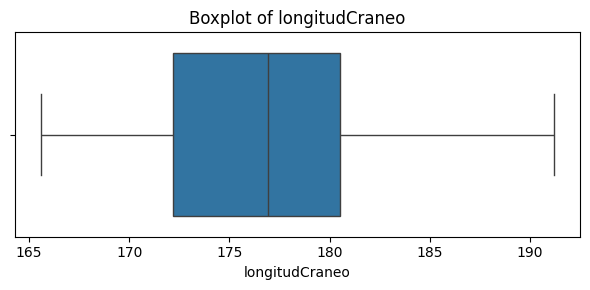

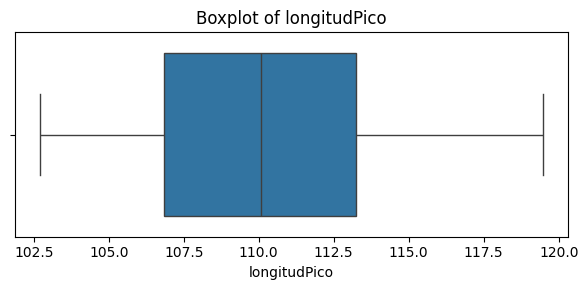

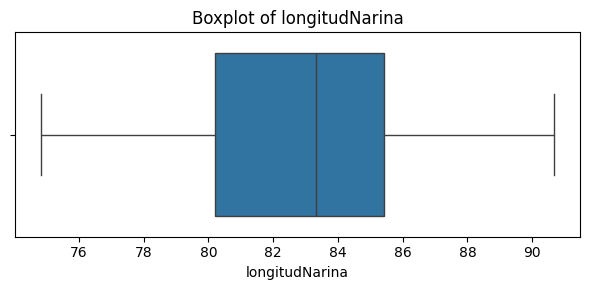

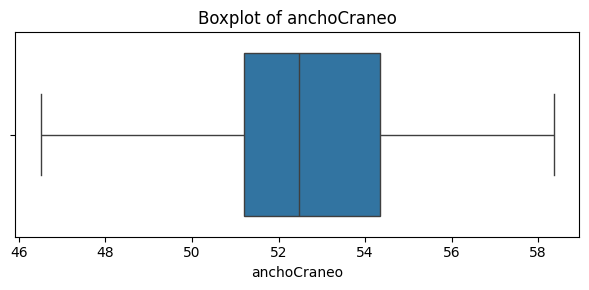

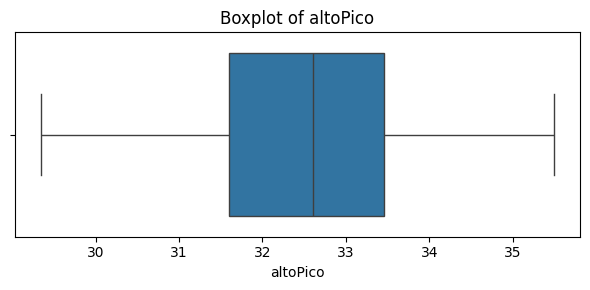

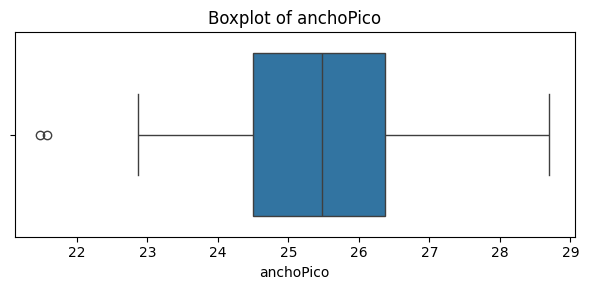

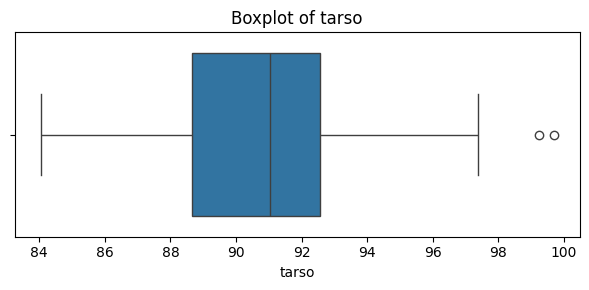

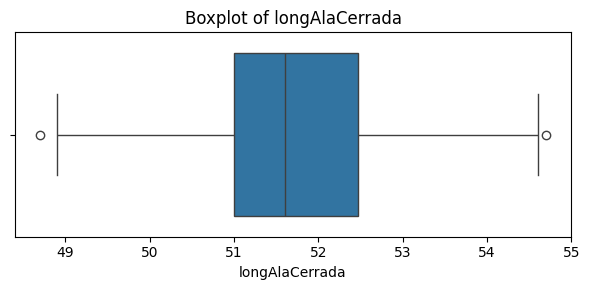

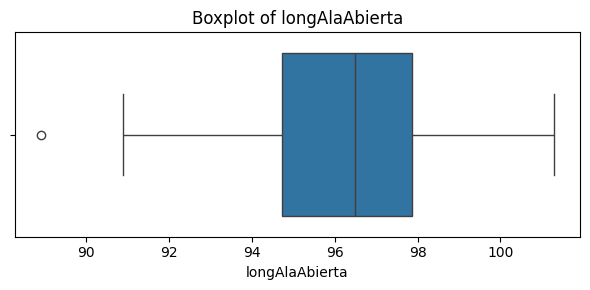

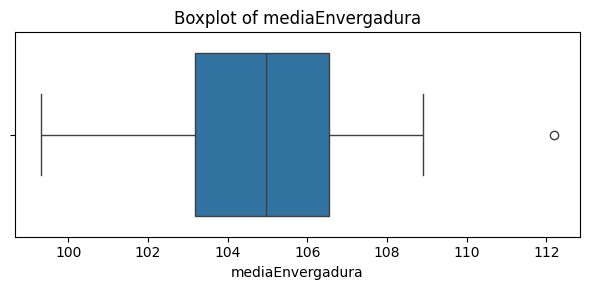

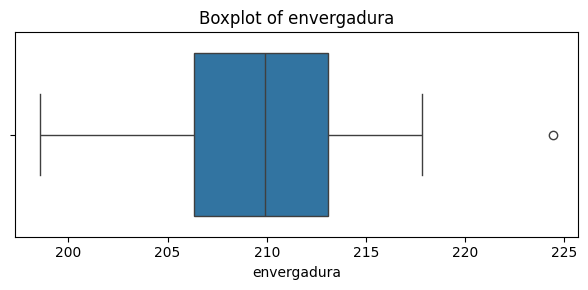

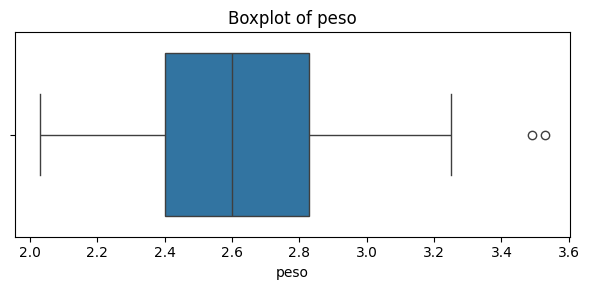

In [78]:
# Visualize outliers using boxplots

for column in X.columns:
    plt.figure(figsize=(6, 3))

    sns.boxplot(x=X[column])

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [79]:

# Separate the independent variables (input features) from the dependent variable (target)
# Exclude 'id' because it is only an identifier and 'sexo' because it is the target variable
X = train.drop(columns=["id", "sexo"])

# Store the target variable (sexo) separately
y = train["sexo"].copy()

# Prepare the test dataset by removing the ID column
X_test = test.drop(columns=["id"])

# Confirm that training and test features match in both names and order.
X_test = X_test.reindex(columns=X.columns)

print("X shape:", X.shape) # Training features dimensions
print("y shape:", y.shape) # Target variable dimensions
print("X_test shape:", X_test.shape) # Test features dimensions
print("Feature columns:", X.columns.tolist()) # Input features used for model training

X shape: (94, 12)
y shape: (94,)
X_test shape: (41, 12)
Feature columns: ['longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']


In [80]:
# Split the dataset into training and validation subsets
# 80% of the data is used for training and 20% for validation
# random_state ensures reproducibility of the split
# stratify=y maintains the same class distribution in both subsets
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_valid.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True))
print("\nValidation class proportions:")
display(y_valid.value_counts(normalize=True))

Training subset: (75, 12)
Validation subset: (19, 12)

Training class proportions:


,proportion
sexo,
H,0.6
M,0.4



Validation class proportions:


,proportion
sexo,
H,0.631579
M,0.368421


In [81]:
# Define classification models using pipelines for preprocessing and model training
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

In [82]:
# Evaluate and Compare models

# Initialize an empty list to store model evaluation results
comparison = []

# Train and evaluate each classification model
for name, pipeline in models.items():
    # Fit the pipeline on the training data
    pipeline.fit(X_train, y_train)
    #  Predict the target labels for the validation dataset
    valid_pred = pipeline.predict(X_valid)

    # Calculate evaluation metrics and store them in the comparison list
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, valid_pred),
        "Precision (H)": precision_score(y_valid, valid_pred, pos_label="H", zero_division=0),
        "Recall (H)": recall_score(y_valid, valid_pred, pos_label="H", zero_division=0),
        "F1 (H)": f1_score(y_valid, valid_pred, pos_label="H", zero_division=0)
    })

comparison_df = pd.DataFrame(comparison).sort_values("F1 (H)", ascending=False)
display(comparison_df)

,Model,Accuracy,Precision (H),Recall (H),F1 (H)
0,Logistic Regression,0.894737,0.916667,0.916667,0.916667
1,KNN,0.894737,0.916667,0.916667,0.916667
4,Random Forest,0.894737,0.916667,0.916667,0.916667
6,Gradient Boosting,0.894737,0.916667,0.916667,0.916667
5,Extra Trees,0.894737,0.916667,0.916667,0.916667
3,Decision Tree,0.842105,0.846154,0.916667,0.880000
2,SVM (RBF),0.789474,0.785714,0.916667,0.846154


In [83]:
# Initialize Stratified K-Fold cross-validation with 5 splits
# shuffle=True randomly shuffles the data before splitting
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

# Perform cross-validation and calculate evaluation metrics for each fold
for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        scoring={
            "f1_H": make_scorer(f1_score, pos_label="H"),
            "precision_H": make_scorer(precision_score, pos_label="H", zero_division=0),
            "recall_H": make_scorer(recall_score, pos_label="H", zero_division=0),
            "accuracy": "accuracy"
        },
        n_jobs=-1
    )
    # Store the mean F1-score, standard deviation of F1-score and mean accuracy
    cv_rows.append({
        "Model": name,
        "Mean CV F1 (H)": scores["test_f1_H"].mean(),
        "Std CV F1 (H)": scores["test_f1_H"].std(),
        "Mean CV Accuracy": scores["test_accuracy"].mean()
    })

cv_comparison = pd.DataFrame(cv_rows).sort_values("Mean CV F1 (H)", ascending=False)
display(cv_comparison)

,Model,Mean CV F1 (H),Std CV F1 (H),Mean CV Accuracy
0,Logistic Regression,0.933265,0.041602,0.920000
5,Extra Trees,0.929248,0.044412,0.920000
2,SVM (RBF),0.929248,0.044412,0.920000
1,KNN,0.917484,0.029348,0.906667
4,Random Forest,0.884735,0.039493,0.866667
6,Gradient Boosting,0.878156,0.043138,0.853333
3,Decision Tree,0.838682,0.051278,0.813333


In [84]:
# Hyperparameter tuning
# Define the models and their hyperparameter grids
tuning_candidates = {
    "Logistic Regression": (
        models["Logistic Regression"],
        {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__penalty": ["l1", "l2"],
            "model__solver": ["liblinear"]
        }
    ),
    "KNN": (
        models["KNN"],
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 20],
            "model__weights": ["uniform", "distance"],
            "model__metric": ["euclidean", "manhattan", "minkowski"]
        }
    ),
    "SVM": (
        models["SVM (RBF)"],
        {
            "model__C": [0.1, 1, 10, 11],
            "model__kernel": ["linear", "rbf", "poly"]
        }
    ),
    "Decision Tree": (
        models["Decision Tree"],
        {
            "model__max_depth": [None, 3, 5, 7, 10],
            "model__min_samples_split": [2, 5, 10],
            "model__criterion": ["gini", "entropy"]
        }
    ),
    "Random Forest": (
        models["Random Forest"],
        {
            "model__n_estimators": [50, 100, 200],
            "model__max_depth": [None, 5, 10, 15],
            "model__min_samples_split": [2, 5, 10],
            "model__criterion": ["gini"]
        }
    )
}

# Use F1-score for H as the scoring metric
f1_h_scorer = make_scorer(f1_score, pos_label=POSITIVE_LABEL, zero_division=0)

tuned_results = []
best_estimators = {}

for name, (pipeline, param_grid) in tuning_candidates.items():
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring=f1_h_scorer,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    best_estimators[name] = grid.best_estimator_
    tuned_results.append({
        "Model": name,
        "Best CV F1 (H)": grid.best_score_,
        "Best parameters": grid.best_params_
    })

tuned_df = pd.DataFrame(tuned_results).sort_values(
    "Best CV F1 (H)", ascending=False
)
display(tuned_df)


,Model,Best CV F1 (H),Best parameters
0,Logistic Regression,0.946013,"{'model__C': 100, 'model__penalty': 'l2', 'mod..."
1,KNN,0.939706,"{'model__metric': 'euclidean', 'model__n_neigh..."
2,SVM,0.937709,"{'model__C': 1, 'model__kernel': 'linear'}"
4,Random Forest,0.909804,"{'model__criterion': 'gini', 'model__max_depth..."
3,Decision Tree,0.860378,"{'model__criterion': 'entropy', 'model__max_de..."


Selected model: Logistic Regression
Accuracy: 0.8947368421052632
Precision for H: 0.9166666666666666
Recall for H: 0.9166666666666666
F1 score for H: 0.9166666666666666

Classification report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19



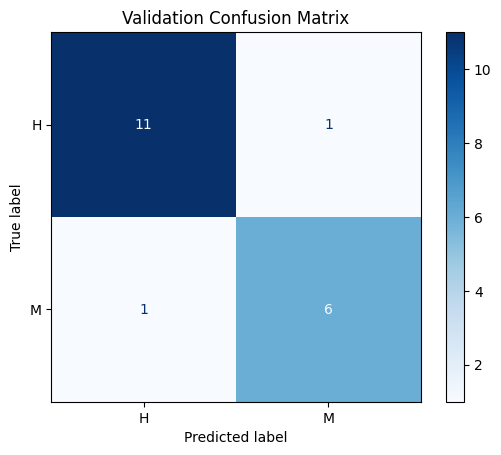

In [85]:
# Select the best-performing model based on the highest cross-validation F1-score
best_name = tuned_df.iloc[0]["Model"]
best_model = best_estimators[best_name]

# Generate predictions on the validation dataset
valid_predictions = best_model.predict(X_valid)

# Evaluate the selected model using different classification metrics
print("Selected model:", best_name)
print("Accuracy:", accuracy_score(y_valid, valid_predictions))
print("Precision for H:", precision_score(y_valid, valid_predictions, pos_label="H", zero_division=0))
print("Recall for H:", recall_score(y_valid, valid_predictions, pos_label="H", zero_division=0))
print("F1 score for H:", f1_score(y_valid, valid_predictions, pos_label="H", zero_division=0))

print("\nClassification report:")
print(classification_report(y_valid, valid_predictions, zero_division=0))

# Generate a confusion matrix to compare actual and predicted class labels
cm = confusion_matrix(y_valid, valid_predictions, labels=["H", "M"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["H", "M"])
disp.plot(cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.show()

In [91]:
# The confusion matrix shows that the model correctly classified 11 female and 6 male birds, while misclassifying 2 records (one female as male and one male as female). It achieved an F1-score of 91.67% for female birds, with a recall of 91.67%, indicating that it correctly identified most of the actual female birds.

In [87]:
final_model = best_model
final_model.fit(X, y)

print("Final model trained on all labelled training records.")

Final model trained on all labelled training records.


In [88]:
test_predictions = final_model.predict(X_test)

print("Number of test predictions:", len(test_predictions))
print("Predicted class counts:")
display(pd.Series(test_predictions).value_counts().rename_axis("sexo").to_frame("Count"))

Number of test predictions: 41
Predicted class counts:


,Count
sexo,
H,22
M,19


In [89]:
submission = pd.DataFrame({
    "id": test["id"],
    "sexo": test_predictions
})

# Match the required column order.
submission = submission[["id", "sexo"]]

# Basic submission checks.
assert list(submission.columns) == ["id", "sexo"]
assert len(submission) == len(test) == 41
assert submission["id"].equals(test["id"])
assert submission["id"].isna().sum() == 0
assert submission["sexo"].isna().sum() == 0
assert set(submission["sexo"].unique()).issubset({"H", "M"})

display(submission.head())
print("Submission shape:", submission.shape)
print("Missing values:", submission.isnull().sum().to_dict())

submission.to_csv("submission.csv", index=False)
print("Saved submission.csv")

,id,sexo
0,A70_2018,M
1,5C9_2018,H
2,5E1_2018,M
3,C58_2018,M
4,5E2_2018,M


Submission shape: (41, 2)
Missing values: {'id': 0, 'sexo': 0}
Saved submission.csv


In [90]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>